# 03 · Preprocessing, Normalisation and Final Dataset

This notebook turns the **cleaned metadata** into the dataset the model is trained on. The target format is deliberately the same as the one the existing model/backend already uses,
so nothing downstream has to change:

| Property | Value (see `src/config.py`) |
|---|---|
| Image size | 100 × 100 px |
| Channels | RGB (3), `uint8` on disk |
| Classes | 24 static letters (`j` and `z` excluded), alphabetical class order |
| Balance | equal number of images per class (cap = 470, the same as the reference paper) |
| Split | 80 % train / 20 % test, stratified by letter |
| Scaling | pixels ÷ 255 → [0, 1]; train-set mean/std saved for optional standardisation |

Steps: filter → balance → split → resize/convert → scale → verify → save.

In [2]:
import sys, warnings
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))      # make `src` importable when running from notebooks/
warnings.filterwarnings("ignore")

import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from src import config, data_utils

sns.set_theme(style="whitegrid", palette="colorblind", font_scale=1.0)
plt.rcParams.update({"figure.dpi": 110, "axes.titleweight": "bold"})
config.IMAGES_DIR.mkdir(exist_ok=True); config.INTERIM_DIR.mkdir(parents=True, exist_ok=True)

def save(fig, name):
    fig.savefig(config.IMAGES_DIR / name, dpi=150, bbox_inches="tight"); print("saved images/" + name)

import json
from sklearn.model_selection import train_test_split
clean = pd.read_csv(config.INTERIM_DIR / "metadata_clean.csv")
clean["path"] = clean["rel_path"].map(lambda p: str(config.DATA_DIR / p))
print(clean.shape)

(63291, 29)


## 1. Filter to the 24 target classes
Only the letters in `config.LETTERS` are kept (cleaning already removed invalid labels; this is a safety net so the class list is always exactly what the model expects).

In [3]:
df = clean[clean.letter.isin(config.LETTERS)].copy()
classes = sorted(config.LETTERS)                       # alphabetical == the order folder-based loaders assign
class_to_idx = {c: i for i, c in enumerate(classes)}
df["label"] = df.letter.map(class_to_idx)
print(len(classes), "classes:", "".join(classes))

24 classes: abcdefghiklmnopqrstuvwxy


## 2. Balance the classes
EDA showed class imbalance, so each class is capped at the same number of images:
`n_per_class = min(SAMPLES_PER_CLASS, size of the smallest class)`. Sampling is random (fixed seed) so every signer present in a class can appear.

Cap per class: 470  (config cap 470, smallest class 2516)
saved images/03_balancing.png


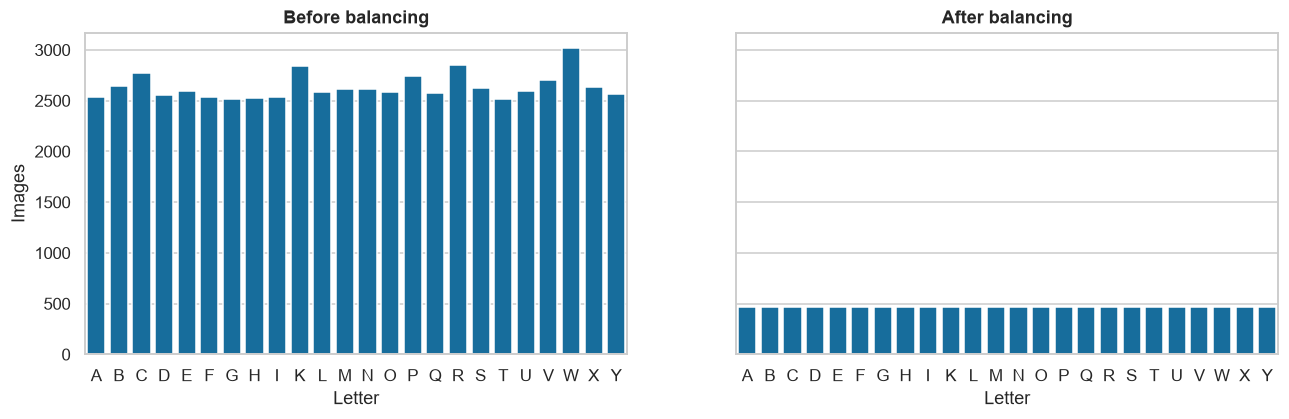

Total after balancing: 11280


In [4]:
n_per_class = int(min(config.SAMPLES_PER_CLASS, df.letter.value_counts().min()))
print(f"Cap per class: {n_per_class}  (config cap {config.SAMPLES_PER_CLASS}, smallest class {df.letter.value_counts().min()})")
bal = pd.concat([g.sample(n_per_class, random_state=config.SEED) for _, g in df.groupby("letter")]).reset_index(drop=True)

fig, axes = plt.subplots(1, 2, figsize=(14, 3.8), sharey=True)
for ax, d, t in zip(axes, [df, bal], ["Before balancing", "After balancing"]):
    c = d.letter.value_counts().reindex(classes)
    sns.barplot(x=[x.upper() for x in c.index], y=c.values, color=sns.color_palette()[0], ax=ax); ax.set_title(t); ax.set_xlabel("Letter")
axes[0].set_ylabel("Images")
save(fig, "03_balancing.png"); plt.show()
print("Total after balancing:", len(bal))

## 3. Train / test split
* **Primary split (matches the previous setup):** stratified random 80/20 → `split` column.
* **Extra, honest check:** because frames from one signer are strongly correlated (see EDA), we also store a **signer-independent** split → `split_signer`: the last signer (alphabetically) is held out entirely as the test set.
  Use it to estimate how the model behaves on a person it has never seen.

Random stratified split: {'train': 9024, 'test': 2256}
Signer-independent split (held-out signer E): {'train': 9138, 'test': 2142}
saved images/03_train_test_split.png


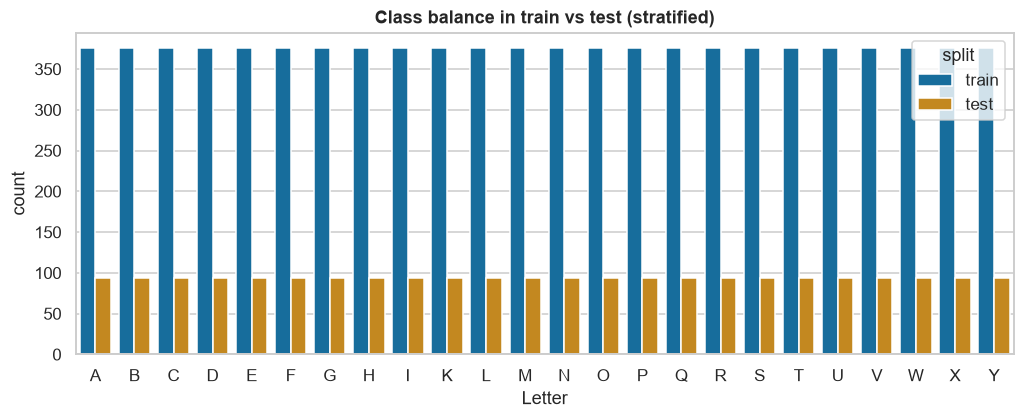

In [5]:
train_idx, test_idx = train_test_split(bal.index, test_size=config.TEST_SIZE, stratify=bal.label, random_state=config.SEED)
bal["split"] = "train"; bal.loc[test_idx, "split"] = "test"

held_out = sorted(bal.user.unique())[-1]
bal["split_signer"] = np.where(bal.user == held_out, "test", "train")
print("Random stratified split:", bal.split.value_counts().to_dict())
print(f"Signer-independent split (held-out signer {held_out}):", bal.split_signer.value_counts().to_dict())

fig, ax = plt.subplots(figsize=(11, 3.8))
sns.countplot(data=bal, x="letter", hue="split", order=classes, ax=ax, palette=sns.color_palette()[:2])
ax.set_xticklabels([c.upper() for c in classes]); ax.set_title("Class balance in train vs test (stratified)"); ax.set_xlabel("Letter")
save(fig, "03_train_test_split.png"); plt.show()

## 4. Standardise format: convert to RGB and resize to 100×100
`data_utils.load_for_model()` applies exactly one transform to every file: **convert to RGB → bilinear resize to 100×100**. This resolves the mixed modes and resolutions found in notebooks 01–02.
Images are written to `data/processed/{train,test}/<letter>/…png` — the same folder-per-class layout a standard image-folder loader expects.

In [6]:
import shutil
out_root = config.PROCESSED_DIR
for s in ["train", "test"]:
    shutil.rmtree(out_root / s, ignore_errors=True)

def write_one(row):
    dst = out_root / row.split / row.letter / f"{row.user}_{row.frame}.png"
    dst.parent.mkdir(parents=True, exist_ok=True)
    data_utils.load_for_model(row.path).save(dst)
    return str(dst.relative_to(config.ROOT))

from concurrent.futures import ThreadPoolExecutor
with ThreadPoolExecutor(8) as ex:
    bal["processed_path"] = list(ex.map(write_one, bal.itertuples(), chunksize=64))

bal.drop(columns=["label"]).assign(label=bal.label).to_csv(config.PROCESSED_DIR / "dataset_index.csv", index=False)
json.dump(class_to_idx, open(config.PROCESSED_DIR / "class_to_idx.json", "w"), indent=2)
print("Wrote", len(bal), "images to", out_root, "+ dataset_index.csv, class_to_idx.json")

Wrote 11280 images to C:\Users\Dell\hand-sign-recognition\data\processed + dataset_index.csv, class_to_idx.json


### Before vs after

saved images/03_before_after_resize.png


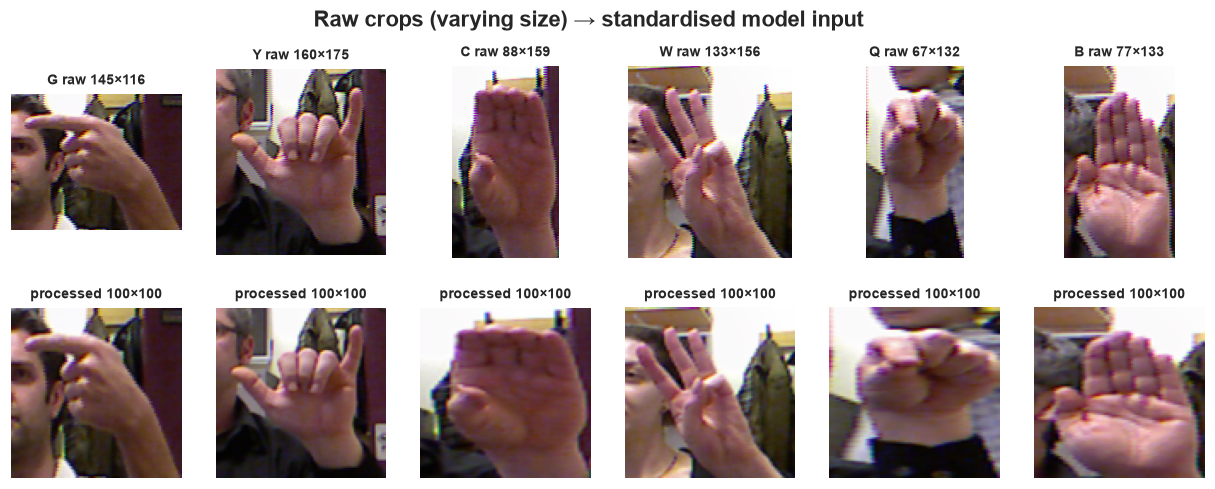

In [7]:
samp = bal.sample(6, random_state=1)
fig, axes = plt.subplots(2, 6, figsize=(14, 5))
for i, r in enumerate(samp.itertuples()):
    from PIL import Image
    orig = Image.open(r.path)
    axes[0, i].imshow(orig); axes[0, i].set_title(f"{r.letter.upper()} raw {orig.width}×{orig.height}", fontsize=9)
    axes[1, i].imshow(Image.open(config.ROOT / r.processed_path)); axes[1, i].set_title("processed 100×100", fontsize=9)
    axes[0, i].axis("off"); axes[1, i].axis("off")
fig.suptitle("Raw crops (varying size) → standardised model input", fontweight="bold")
save(fig, "03_before_after_resize.png"); plt.show()

## 5. Normalisation / scaling
Pixel values are scaled from [0, 255] to **[0, 1]** (÷ 255). We also compute the **per-channel mean and standard deviation on the training set only** (never on test, to avoid leakage) and save them,
in case the model uses standardisation `(x − mean) / std`. Arrays are stored as `uint8` to keep files small; scaling happens at load time with the helper below.

In [11]:
def load_split(split):
    sub = bal[bal.split == split]
    X = np.stack([np.asarray(Image.open(config.ROOT / p)) for p in sub.processed_path]).astype("uint8")
    return X, sub.label.values.astype("int64")

X_train, y_train = load_split("train")
X_test, y_test = load_split("test")
print("X_train", X_train.shape, X_train.dtype, "| X_test", X_test.shape, X_test.dtype)

Xs = X_train.astype("float32") / 255.0
mean, std = Xs.mean(axis=(0, 1, 2), dtype="float64"), Xs.std(axis=(0, 1, 2), dtype="float64")
stats = {"scale": "x/255", "mean_rgb": mean.round(5).tolist(), "std_rgb": std.round(5).tolist(), "img_size": config.IMG_SIZE, "channels": 3,
         "n_train": int(len(X_train)), "n_test": int(len(X_test)), "classes": classes}
json.dump(stats, open(config.PROCESSED_DIR / "normalization_stats.json", "w"), indent=2)
print("Train mean (RGB):", mean.round(4), "| std:", std.round(4))

np.savez_compressed(config.PROCESSED_DIR / "gesture_dataset_uint8.npz", X_train=X_train, y_train=y_train, X_test=X_test, y_test=y_test)
print("saved data/processed/gesture_dataset_uint8.npz")

X_train (9024, 100, 100, 3) uint8 | X_test (2256, 100, 100, 3) uint8
Train mean (RGB): [0.4672 0.356  0.3547] | std: [0.2706 0.2677 0.2632]
saved data/processed/gesture_dataset_uint8.npz


saved images/03_normalization_histograms.png


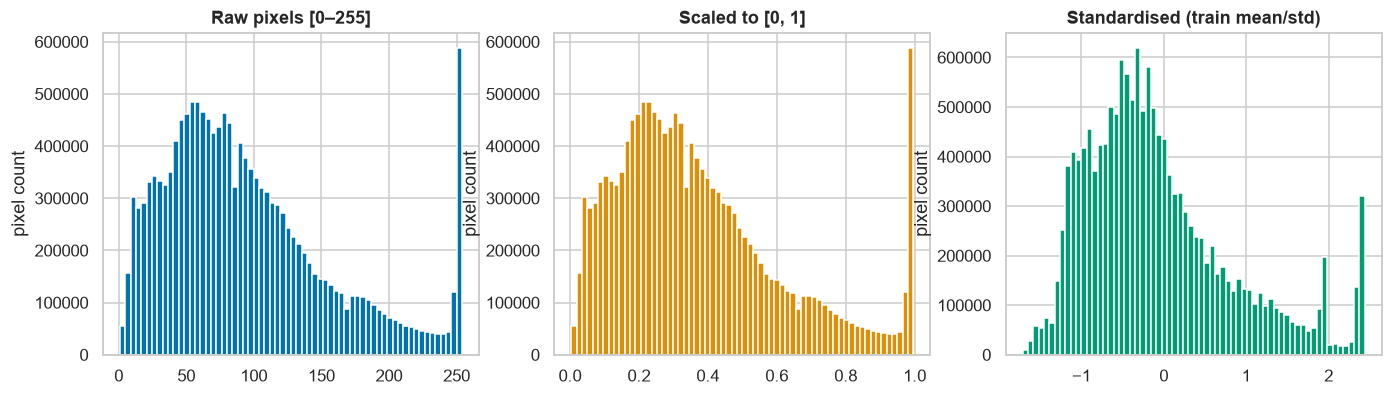

[0,1] range: min=0.00 max=1.00 | standardised: mean=0.000 std=1.000


In [12]:
Xstd = (Xs - mean) / std
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
axes[0].hist(X_train[:500].ravel(), bins=64, color=sns.color_palette()[0]); axes[0].set_title("Raw pixels [0–255]")
axes[1].hist(Xs[:500].ravel(), bins=64, color=sns.color_palette()[1]); axes[1].set_title("Scaled to [0, 1]")
axes[2].hist(Xstd[:500].ravel(), bins=64, color=sns.color_palette()[2]); axes[2].set_title("Standardised (train mean/std)")
for a in axes: a.set_ylabel("pixel count")
save(fig, "03_normalization_histograms.png"); plt.show()
print(f"[0,1] range: min={Xs.min():.2f} max={Xs.max():.2f} | standardised: mean={Xstd.mean():.3f} std={Xstd.std():.3f}")

**What it tells us:** scaling keeps the *shape* of the pixel distribution and only changes its range; standardising centres each channel around 0 with unit variance, which usually speeds up and stabilises training.
Use `x/255` if the existing model was trained that way, or standardisation if it was trained with mean/std — the stats file has both.

## 6. Verification: the processed set must match the model's input format

In [10]:
assert X_train.shape[1:] == (config.IMG_SIZE, config.IMG_SIZE, 3) and X_test.shape[1:] == X_train.shape[1:]
assert X_train.dtype == np.uint8
assert set(np.unique(y_train)) == set(np.unique(y_test)) == set(range(len(classes)))
assert Xs.min() >= 0 and Xs.max() <= 1
# no file appears in both splits (no train/test leakage by identical path / md5)
tr, te = bal[bal.split == "train"], bal[bal.split == "test"]
assert not (set(tr.md5) & set(te.md5)), "identical images in train and test!"
chk = Image.open(config.ROOT / bal.processed_path.iloc[0]); assert chk.size == (100, 100) and chk.mode == "RGB"
print("All checks passed ✔")
print(pd.DataFrame({"train": tr.letter.value_counts(), "test": te.letter.value_counts()}).reindex(classes).T.to_string())

All checks passed ✔
letter    a    b    c    d    e    f    g    h    i    k    l    m    n    o    p    q    r    s    t    u    v    w    x    y
train   376  376  376  376  376  376  376  376  376  376  376  376  376  376  376  376  376  376  376  376  376  376  376  376
test     94   94   94   94   94   94   94   94   94   94   94   94   94   94   94   94   94   94   94   94   94   94   94   94


## Output of Phase 1
```
data/processed/
├── train/<letter>/*.png        100×100 RGB, balanced, 80 %
├── test/<letter>/*.png         100×100 RGB, balanced, 20 %
├── dataset_index.csv           one row per image: letter, label, signer, split, split_signer, raw & processed path
├── class_to_idx.json           alphabetical class → index map (24 classes)
├── normalization_stats.json    train-set mean/std, scaling rule
└── gesture_dataset_uint8.npz   the same data as arrays (uint8)
```
Re-running the three notebooks in order regenerates everything from the raw download.